<a href="https://colab.research.google.com/github/rontalapoojareddy/M.T-Project/blob/main/MTech_IDS_Research_V3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ==========================================================
# M.TECH RESEARCH V3 - CELL 1
# Environment Setup and Reproducibility
# ==========================================================

import os
import sys
import json
import platform
import importlib
from datetime import datetime, timezone

# Create folders to store V3 research outputs
BASE_DIR = "/content/MTech_IDS_V3"
DATA_DIR = os.path.join(BASE_DIR, "data")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULT_DIR = os.path.join(BASE_DIR, "results")
GRAPH_DIR = os.path.join(BASE_DIR, "graphs")

for folder in [DATA_DIR, MODEL_DIR, RESULT_DIR, GRAPH_DIR]:
    os.makedirs(folder, exist_ok=True)

# Check required packages
packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scikit-learn": "sklearn",
    "xgboost": "xgboost",
    "matplotlib": "matplotlib",
    "imbalanced-learn": "imblearn",
    "joblib": "joblib"
}

versions = {}
missing = []

for display_name, module_name in packages.items():
    try:
        module = importlib.import_module(module_name)
        versions[display_name] = getattr(
            module, "__version__", "installed"
        )
        print(f"PASS: {display_name} - {versions[display_name]}")
    except ImportError:
        missing.append(display_name)
        print(f"MISSING: {display_name}")

# Save environment details
environment = {
    "project": "MTech IDS Research V3",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "packages": versions,
    "missing_packages": missing
}

with open(
    os.path.join(BASE_DIR, "environment.json"), "w"
) as f:
    json.dump(environment, f, indent=4)

print("\n" + "=" * 55)
print("V3 ENVIRONMENT CHECK COMPLETED")
print("=" * 55)
print("Project directory:", BASE_DIR)

if missing:
    print("Packages requiring installation:", missing)
else:
    print("All required packages are available.")

print("\nResearch folders created successfully.")


PASS: numpy - 2.4.6
PASS: pandas - 2.2.3
PASS: scikit-learn - 1.6.1
PASS: xgboost - 3.4.1
PASS: matplotlib - 3.10.0
PASS: imbalanced-learn - 0.14.2
PASS: joblib - 1.6.0

V3 ENVIRONMENT CHECK COMPLETED
Project directory: /content/MTech_IDS_V3
All required packages are available.

Research folders created successfully.


In [3]:

# =====================================================
# M.TECH RESEARCH V3 - CELL 2 (CORRECTED)
# UNSW-NB15 Dataset Download and Verification
# =====================================================

import os
import hashlib
import pandas as pd
import urllib.request

base_url = (
    "https://raw.githubusercontent.com/Nir-J/"
    "ML-Projects/master/"
    "UNSW-Network_Packet_Classification/"
)

files_info = {
    "train": ("UNSW_NB15_training-set.csv", 175341),
    "test": ("UNSW_NB15_testing-set.csv", 82332)
}

dataframes = {}

for name, (filename, expected_rows) in files_info.items():

    path = os.path.join(DATA_DIR, filename)
    url = base_url + filename

    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print(f"Downloading {filename}...")
        urllib.request.urlretrieve(url, path)

    df = pd.read_csv(path)

    assert df.shape == (expected_rows, 45), (
        f"Unexpected shape for {filename}: {df.shape}"
    )

    required = {"id", "attack_cat", "label"}
    assert required.issubset(df.columns)

    with open(path, "rb") as f:
        sha256 = hashlib.file_digest(f, "sha256").hexdigest()

    dataframes[name] = df

    print(f"\n{name.upper()} DATASET")
    print("Shape:", df.shape)
    print("SHA256:", sha256)
    print("Missing values:", int(df.isna().sum().sum()))

train_df = dataframes["train"]
test_df = dataframes["test"]

assert list(train_df.columns) == list(test_df.columns)

print("\n" + "=" * 55)
print("V3 DATASET VERIFICATION")
print("=" * 55)

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Total records:", len(train_df) + len(test_df))

print("\nTraining attack categories:")
print(train_df["attack_cat"].value_counts())

print("\nTesting attack categories:")
print(test_df["attack_cat"].value_counts())

print("\nSUCCESS: Dataset files loaded.")
print("Next step: Verify V2 split and prepare V3 data.")



TRAIN DATASET
Shape: (175341, 45)
SHA256: bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa
Missing values: 0

TEST DATASET
Shape: (82332, 45)
SHA256: 734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559
Missing values: 0

V3 DATASET VERIFICATION
Training records: 175341
Testing records: 82332
Total records: 257673

Training attack categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Testing attack categories:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

SUCCESS: Dataset files loaded.
Next step: V

In [4]:

# ==========================================================
# M.TECH RESEARCH V3 - CELL 3
# Training / Validation Split
# ==========================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

SEED = 42
VALIDATION_FRACTION = 0.20

# Binary target: 0 = Normal, 1 = Attack
y_binary = train_df["label"].astype(int)

# Keep V2-style stratification on binary labels
train_indices, val_indices = train_test_split(
    np.arange(len(train_df)),
    test_size=VALIDATION_FRACTION,
    random_state=SEED,
    stratify=y_binary
)

v3_train = train_df.iloc[train_indices].copy()
v3_val = train_df.iloc[val_indices].copy()
v3_test = test_df.copy()

# Save the row indices for reproducibility
np.save(
    os.path.join(DATA_DIR, "train_indices.npy"),
    train_indices
)
np.save(
    os.path.join(DATA_DIR, "validation_indices.npy"),
    val_indices
)

print("=" * 55)
print("V3 TRAIN / VALIDATION / TEST SPLIT")
print("=" * 55)

print("Training records:", len(v3_train))
print("Validation records:", len(v3_val))
print("Untouched test records:", len(v3_test))

print("\nTraining binary distribution:")
print(v3_train["label"].value_counts())

print("\nValidation binary distribution:")
print(v3_val["label"].value_counts())

print("\nTraining attack category distribution:")
print(v3_train["attack_cat"].value_counts())

print("\nValidation attack category distribution:")
print(v3_val["attack_cat"].value_counts())

# Check for overlap between training and validation rows
assert set(train_indices).isdisjoint(set(val_indices))
assert len(train_indices) + len(val_indices) == len(train_df)

metadata = {
    "seed": SEED,
    "validation_fraction": VALIDATION_FRACTION,
    "stratification": "binary label",
    "train_rows": len(v3_train),
    "validation_rows": len(v3_val),
    "test_rows": len(v3_test),
    "train_sha256": (
        "bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa"
    ),
    "test_sha256": (
        "734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559"
    )
}

with open(
    os.path.join(BASE_DIR, "split_metadata.json"), "w"
) as f:
    json.dump(metadata, f, indent=4)

print("\nSUCCESS: Data split completed.")
print("No overlapping train/validation row indices.")
print("Official test dataset remains separate.")


V3 TRAIN / VALIDATION / TEST SPLIT
Training records: 140272
Validation records: 35069
Untouched test records: 82332

Training binary distribution:
label
1    95472
0    44800
Name: count, dtype: int64

Validation binary distribution:
label
1    23869
0    11200
Name: count, dtype: int64

Training attack category distribution:
attack_cat
Normal            44800
Generic           31995
Exploits          26810
Fuzzers           14510
DoS                9781
Reconnaissance     8356
Analysis           1578
Backdoor           1432
Shellcode           908
Worms               102
Name: count, dtype: int64

Validation attack category distribution:
attack_cat
Normal            11200
Generic            8005
Exploits           6583
Fuzzers            3674
DoS                2483
Reconnaissance     2135
Analysis            422
Backdoor            314
Shellcode           225
Worms                28
Name: count, dtype: int64

SUCCESS: Data split completed.
No overlapping train/validation row indices.

In [5]:

# ==========================================================
# M.TECH RESEARCH V3 - CELL 4
# Feature Preprocessing and Target Preparation
# ==========================================================

import os
import json
import joblib
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("=" * 60)
print("V3 - FEATURE PREPROCESSING")
print("=" * 60)

# ----------------------------------------------------------
# STEP 1: Separate input features and target variables
# ----------------------------------------------------------

DROP_COLUMNS = ["id", "label", "attack_cat"]

FEATURE_COLUMNS = [
    col for col in v3_train.columns
    if col not in DROP_COLUMNS
]

X_train_raw = v3_train[FEATURE_COLUMNS].copy()
X_val_raw = v3_val[FEATURE_COLUMNS].copy()
X_test_raw = v3_test[FEATURE_COLUMNS].copy()

# Binary labels: 0 = Normal, 1 = Attack
y_train_binary = v3_train["label"].astype(int).to_numpy()
y_val_binary = v3_val["label"].astype(int).to_numpy()
y_test_binary = v3_test["label"].astype(int).to_numpy()

# Multiclass labels: attack category names
y_train_multi = v3_train["attack_cat"].astype(str).to_numpy()
y_val_multi = v3_val["attack_cat"].astype(str).to_numpy()
y_test_multi = v3_test["attack_cat"].astype(str).to_numpy()

print("\nOriginal input features:", len(FEATURE_COLUMNS))

# ----------------------------------------------------------
# STEP 2: Identify categorical and numerical columns
# ----------------------------------------------------------

CATEGORICAL_COLUMNS = [
    "proto",
    "service",
    "state"
]

NUMERICAL_COLUMNS = [
    col for col in FEATURE_COLUMNS
    if col not in CATEGORICAL_COLUMNS
]

assert all(
    col in FEATURE_COLUMNS for col in CATEGORICAL_COLUMNS
), "One or more categorical columns are missing."

print("Categorical features:", CATEGORICAL_COLUMNS)
print("Numerical features:", len(NUMERICAL_COLUMNS))

# ----------------------------------------------------------
# STEP 3: Create preprocessing pipeline
# ----------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAL_COLUMNS
        ),
        (
            "numerical",
            StandardScaler(),
            NUMERICAL_COLUMNS
        )
    ],
    remainder="drop",
    sparse_threshold=0.0
)

# IMPORTANT:
# Fit only on training data to prevent data leakage.
print("\nFitting preprocessor on training data...")

X_train = preprocessor.fit_transform(X_train_raw)

print("Transforming validation data...")
X_val = preprocessor.transform(X_val_raw)

print("Transforming untouched test data...")
X_test = preprocessor.transform(X_test_raw)

# Use float32 to reduce RAM usage
X_train = np.asarray(X_train, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

# ----------------------------------------------------------
# STEP 4: Prepare attack-only multiclass datasets
# ----------------------------------------------------------

train_attack_mask = y_train_binary == 1
val_attack_mask = y_val_binary == 1
test_attack_mask = y_test_binary == 1

X_train_attack = X_train[train_attack_mask]
X_val_attack = X_val[val_attack_mask]
X_test_attack = X_test[test_attack_mask]

y_train_attack = y_train_multi[train_attack_mask]
y_val_attack = y_val_multi[val_attack_mask]
y_test_attack = y_test_multi[test_attack_mask]

# ----------------------------------------------------------
# STEP 5: Verify dataset dimensions
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("PREPROCESSING RESULTS")
print("=" * 60)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nAttack-only datasets:")
print("Training:", X_train_attack.shape)
print("Validation:", X_val_attack.shape)
print("Testing:", X_test_attack.shape)

print("\nMissing or infinite values:")
for name, data in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test)
]:
    invalid_count = int((~np.isfinite(data)).sum())
    print(f"{name}: {invalid_count}")
    assert invalid_count == 0, f"Invalid values in {name}"

assert X_train.shape[1] == X_val.shape[1]
assert X_train.shape[1] == X_test.shape[1]

# ----------------------------------------------------------
# STEP 6: Save preprocessing objects
# ----------------------------------------------------------

preprocessor_path = os.path.join(
    MODEL_DIR, "v3_preprocessor.joblib"
)

joblib.dump(
    {
        "preprocessor": preprocessor,
        "feature_columns": FEATURE_COLUMNS,
        "categorical_columns": CATEGORICAL_COLUMNS,
        "numerical_columns": NUMERICAL_COLUMNS
    },
    preprocessor_path
)

metadata = {
    "raw_features": len(FEATURE_COLUMNS),
    "processed_features": int(X_train.shape[1]),
    "categorical_features": CATEGORICAL_COLUMNS,
    "numerical_feature_count": len(NUMERICAL_COLUMNS),
    "training_records": len(X_train),
    "validation_records": len(X_val),
    "test_records": len(X_test),
    "training_attack_records": len(X_train_attack),
    "validation_attack_records": len(X_val_attack),
    "test_attack_records": len(X_test_attack)
}

with open(
    os.path.join(RESULT_DIR, "preprocessing_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("\nPreprocessor saved to:", preprocessor_path)
print("\nSUCCESS: CELL 4 COMPLETED.")
print("Ready for V3 model training.")


V3 - FEATURE PREPROCESSING

Original input features: 42
Categorical features: ['proto', 'service', 'state']
Numerical features: 39

Fitting preprocessor on training data...
Transforming validation data...
Transforming untouched test data...

PREPROCESSING RESULTS
Training features: (140272, 192)
Validation features: (35069, 192)
Testing features: (82332, 192)

Attack-only datasets:
Training: (95472, 192)
Validation: (23869, 192)
Testing: (45332, 192)

Missing or infinite values:
Train: 0
Validation: 0
Test: 0

Preprocessor saved to: /content/MTech_IDS_V3/models/v3_preprocessor.joblib

SUCCESS: CELL 4 COMPLETED.
Ready for V3 model training.


In [6]:

# ==========================================================
# M.TECH RESEARCH V3 - CELL 5
# Imbalance-Aware Multiclass Model Training
# ==========================================================

import os
import gc
import time
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

print("=" * 65)
print("V3 - IMBALANCE-AWARE MODEL TRAINING")
print("=" * 65)

# Use the attack-only data prepared in Cell 4.
# The official test data will NOT be used in this cell.

assert X_train_attack.shape[0] == len(y_train_attack)
assert X_val_attack.shape[0] == len(y_val_attack)

SEED = 42

# Keep identical parameters except for class weighting.
# This makes the comparison easier to interpret.
model_settings = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "random_state": SEED,
    "n_jobs": 2
}

experiments = {
    "Standard_RF": None,
    "Weighted_RF": "balanced",
    "Balanced_Subsample_RF": "balanced_subsample"
}

classes = sorted(np.unique(y_train_attack))

validation_results = []
per_class_results = []
trained_model_paths = {}

for model_name, weight_setting in experiments.items():

    print("\n" + "-" * 65)
    print("Training:", model_name)
    print("Class weight:", weight_setting)
    print("-" * 65)

    start_time = time.time()

    model = RandomForestClassifier(
        **model_settings,
        class_weight=weight_setting
    )

    model.fit(X_train_attack, y_train_attack)

    training_seconds = time.time() - start_time

    # Validation only - no official test predictions
    predictions = model.predict(X_val_attack)

    accuracy = accuracy_score(
        y_val_attack, predictions
    )

    macro_f1 = f1_score(
        y_val_attack,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val_attack,
        predictions,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_val_attack, predictions
    )

    report = classification_report(
        y_val_attack,
        predictions,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
        "Balanced_Accuracy": balanced_acc,
        "Training_Seconds": training_seconds
    })

    for attack_class in classes:
        per_class_results.append({
            "Model": model_name,
            "Attack_Class": attack_class,
            "Precision": report[attack_class]["precision"],
            "Recall": report[attack_class]["recall"],
            "F1": report[attack_class]["f1-score"],
            "Support": report[attack_class]["support"]
        })

    # Save each model immediately to protect progress
    model_path = os.path.join(
        MODEL_DIR, model_name + ".joblib"
    )

    joblib.dump(model, model_path, compress=3)
    trained_model_paths[model_name] = model_path

    # Save intermediate reports after every model
    results_df = pd.DataFrame(validation_results)

    results_df.to_csv(
        os.path.join(
            RESULT_DIR, "v3_validation_comparison.csv"
        ),
        index=False
    )

    pd.DataFrame(per_class_results).to_csv(
        os.path.join(
            RESULT_DIR, "v3_per_class_validation.csv"
        ),
        index=False
    )

    print(f"Accuracy          : {accuracy:.4f}")
    print(f"Macro-F1          : {macro_f1:.4f}")
    print(f"Weighted-F1       : {weighted_f1:.4f}")
    print(f"Balanced Accuracy : {balanced_acc:.4f}")
    print(f"Training time     : {training_seconds:.1f} seconds")
    print("Model saved:", model_path)

    del model, predictions
    gc.collect()

# ----------------------------------------------------------
# Final validation comparison
# ----------------------------------------------------------

results_df = pd.DataFrame(validation_results)

results_df = results_df.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("V3 VALIDATION MODEL COMPARISON")
print("=" * 65)

print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]["Model"]
best_macro_f1 = float(results_df.iloc[0]["Macro_F1"])

selection = {
    "selected_model": best_model_name,
    "selection_metric": "Validation Macro-F1",
    "validation_macro_f1": best_macro_f1,
    "model_path": trained_model_paths[best_model_name],
    "random_seed": SEED,
    "test_set_used_for_selection": False,
    "model_settings": model_settings
}

with open(
    os.path.join(RESULT_DIR, "v3_model_selection.json"),
    "w"
) as f:
    json.dump(selection, f, indent=4)

print("\n" + "=" * 65)
print("SELECTED V3 MODEL:", best_model_name)
print(f"VALIDATION MACRO-F1: {best_macro_f1:.4f}")
print("=" * 65)

print("\nSUCCESS: CELL 5 COMPLETED.")
print("Models and validation reports saved.")
print("Official test set has not been evaluated.")


V3 - IMBALANCE-AWARE MODEL TRAINING

-----------------------------------------------------------------
Training: Standard_RF
Class weight: None
-----------------------------------------------------------------
Accuracy          : 0.8013
Macro-F1          : 0.5771
Weighted-F1       : 0.7885
Balanced Accuracy : 0.5411
Training time     : 23.5 seconds
Model saved: /content/MTech_IDS_V3/models/Standard_RF.joblib

-----------------------------------------------------------------
Training: Weighted_RF
Class weight: balanced
-----------------------------------------------------------------
Accuracy          : 0.7443
Macro-F1          : 0.5596
Weighted-F1       : 0.7758
Balanced Accuracy : 0.5541
Training time     : 18.8 seconds
Model saved: /content/MTech_IDS_V3/models/Weighted_RF.joblib

-----------------------------------------------------------------
Training: Balanced_Subsample_RF
Class weight: balanced_subsample
-----------------------------------------------------------------
Accuracy  

V3 - MINORITY ATTACK PERFORMANCE ANALYSIS

MINORITY ATTACK F1 COMPARISON:
Model         Balanced_Subsample_RF  Standard_RF  Weighted_RF
Attack_Class                                                 
Analysis                     0.1340       0.3340       0.1348
Backdoor                     0.0627       0.2257       0.0583
DoS                          0.3460       0.2362       0.3458
Shellcode                    0.6489       0.6725       0.6593
Worms                        0.4348       0.2632       0.4545

MINORITY ATTACK RECALL COMPARISON:
Model         Balanced_Subsample_RF  Standard_RF  Weighted_RF
Attack_Class                                                 
Analysis                     0.2156       0.2085       0.2156
Backdoor                     0.1815       0.1369       0.1688
DoS                          0.4205       0.1909       0.4205
Shellcode                    0.6489       0.6844       0.6622
Worms                        0.3571       0.1786       0.3571


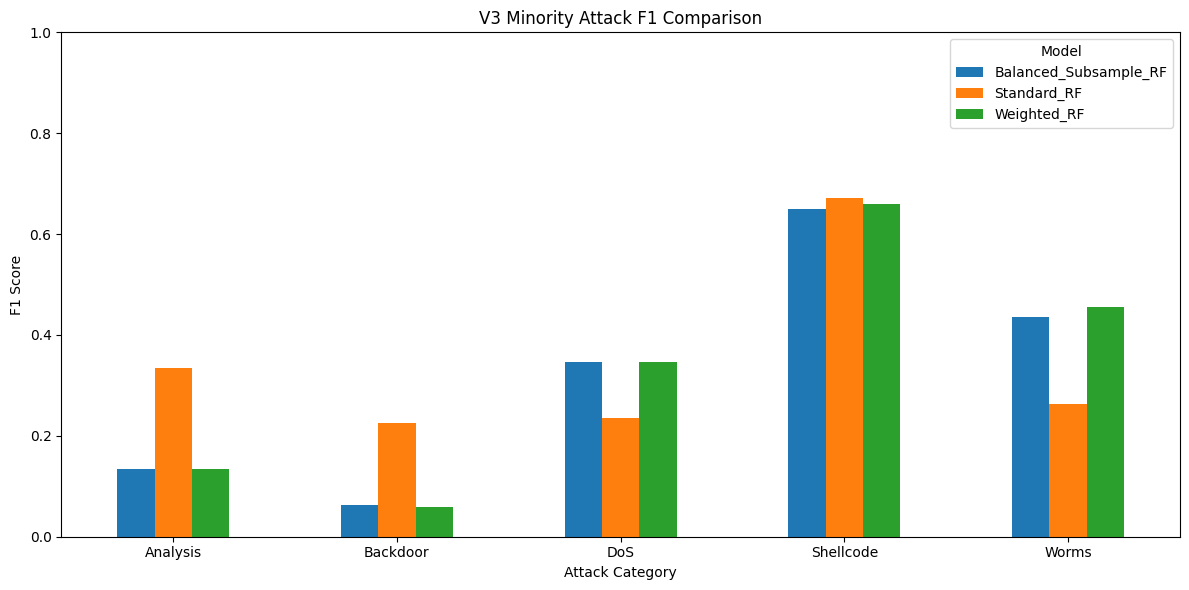


Graph saved: /content/MTech_IDS_V3/graphs/minority_attack_f1.png

BEST VALIDATION MODEL BY ATTACK CATEGORY:
Attack_Class
Analysis               Standard_RF
Backdoor               Standard_RF
DoS          Balanced_Subsample_RF
Shellcode              Standard_RF
Worms                  Weighted_RF

SUCCESS: CELL 6 COMPLETED.


In [7]:

# ==========================================================
# M.TECH RESEARCH V3 - CELL 6
# Minority Attack Performance Analysis
# ==========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 65)
print("V3 - MINORITY ATTACK PERFORMANCE ANALYSIS")
print("=" * 65)

# Load saved validation results
comparison = pd.read_csv(
    os.path.join(RESULT_DIR, "v3_validation_comparison.csv")
)

per_class = pd.read_csv(
    os.path.join(RESULT_DIR, "v3_per_class_validation.csv")
)

# Focus on the weakest attack categories
minority_classes = [
    "Analysis",
    "Backdoor",
    "DoS",
    "Shellcode",
    "Worms"
]

minority_results = per_class[
    per_class["Attack_Class"].isin(minority_classes)
].copy()

# Compare per-class F1 scores
f1_table = minority_results.pivot(
    index="Attack_Class",
    columns="Model",
    values="F1"
)

print("\nMINORITY ATTACK F1 COMPARISON:")
print(f1_table.round(4).to_string())

# Compare recall
recall_table = minority_results.pivot(
    index="Attack_Class",
    columns="Model",
    values="Recall"
)

print("\nMINORITY ATTACK RECALL COMPARISON:")
print(recall_table.round(4).to_string())

# Save detailed comparisons
f1_table.to_csv(
    os.path.join(RESULT_DIR, "minority_f1_comparison.csv")
)

recall_table.to_csv(
    os.path.join(RESULT_DIR, "minority_recall_comparison.csv")
)

# Generate graph
ax = f1_table.plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

ax.set_title("V3 Minority Attack F1 Comparison")
ax.set_ylabel("F1 Score")
ax.set_xlabel("Attack Category")
ax.set_ylim(0, 1)
ax.legend(title="Model")

plt.tight_layout()

graph_path = os.path.join(
    GRAPH_DIR, "minority_attack_f1.png"
)

plt.savefig(graph_path, dpi=200)
plt.show()

print("\nGraph saved:", graph_path)

# Show best method for each minority category
best_per_class = f1_table.idxmax(axis=1)

print("\nBEST VALIDATION MODEL BY ATTACK CATEGORY:")
print(best_per_class.to_string())

print("\nSUCCESS: CELL 6 COMPLETED.")


V3 - FINAL UNTOUCHED TEST EVALUATION
Selected model: Standard_RF
Validation Macro-F1: 0.5770562155047751

FINAL TEST METRICS:
Accuracy: 0.7765
Macro_F1: 0.4754
Weighted_F1: 0.7762
Balanced_Accuracy: 0.4753

PER-CLASS TEST REPORT:
                precision  recall  f1-score     support
Analysis           0.0059  0.0059    0.0059    677.0000
Backdoor           0.0193  0.1012    0.0324    583.0000
DoS                0.6796  0.0898    0.1586   4089.0000
Exploits           0.6510  0.7934    0.7152  11132.0000
Fuzzers            0.8085  0.7656    0.7865   6062.0000
Generic            0.9992  0.9674    0.9830  18871.0000
Reconnaissance     0.9330  0.7972    0.8598   3496.0000
Shellcode          0.5185  0.6667    0.5833    378.0000
Worms              0.5000  0.0909    0.1538     44.0000
accuracy           0.7765  0.7765    0.7765      0.7765
macro avg          0.5684  0.4753    0.4754  45332.0000
weighted avg       0.8223  0.7765    0.7762  45332.0000


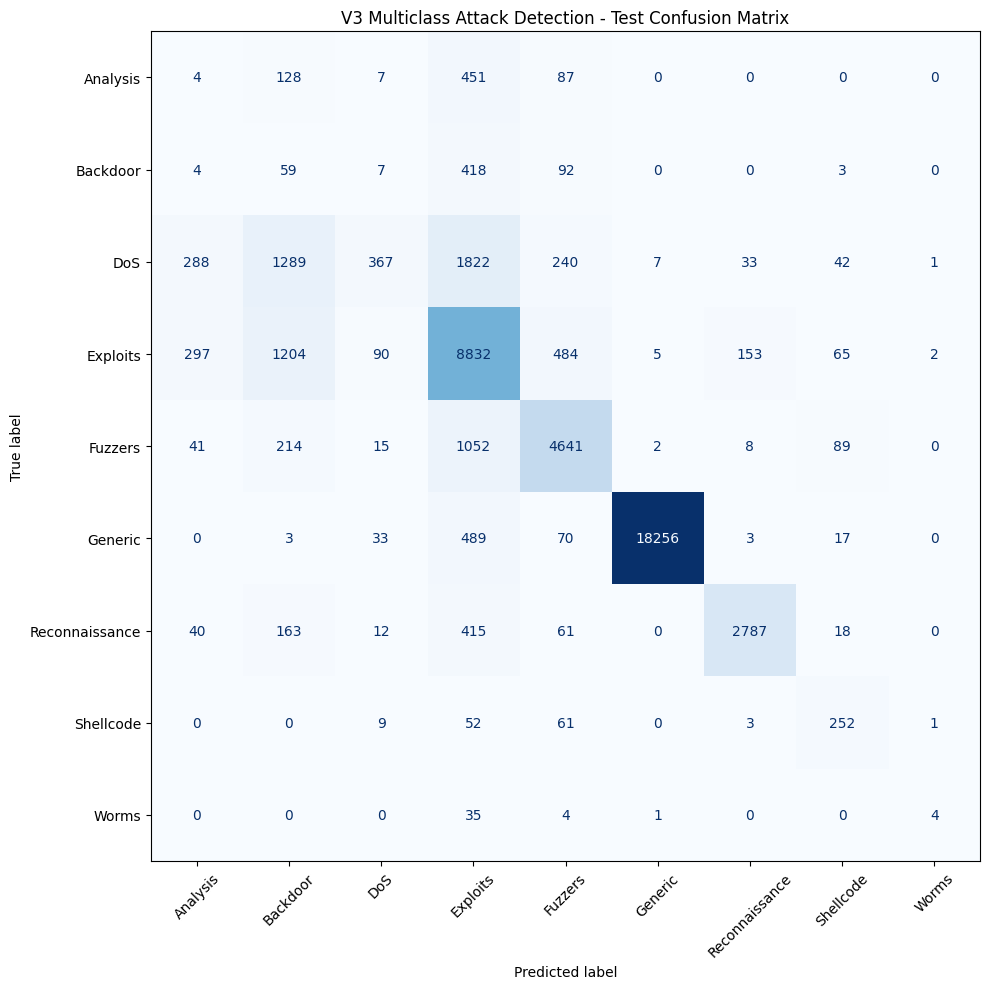


Confusion matrix saved: /content/MTech_IDS_V3/graphs/v3_test_confusion_matrix.png

V2 vs V3 MULTICLASS TEST COMPARISON
V2 Macro-F1: 0.5222
V3 Macro-F1: 0.4754
Difference: -4.68 percentage points

Note: This is a descriptive comparison.
It does not establish statistical significance
or prove that class weighting caused an improvement.

SUCCESS: CELL 7 COMPLETED.


In [8]:

# ==========================================================
# M.TECH RESEARCH V3 - CELL 7
# Final Test Evaluation of Selected Multiclass Model
# ==========================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("=" * 65)
print("V3 - FINAL UNTOUCHED TEST EVALUATION")
print("=" * 65)

# 1. Load the model selected using validation Macro-F1
selection_path = os.path.join(
    RESULT_DIR, "v3_model_selection.json"
)

with open(selection_path, "r") as f:
    selection = json.load(f)

selected_name = selection["selected_model"]

assert selection["selection_metric"] == "Validation Macro-F1"
assert selected_name == "Standard_RF", (
    "Unexpected selection: review Cell 5 results first."
)

print("Selected model:", selected_name)
print("Validation Macro-F1:", selection["validation_macro_f1"])

model = joblib.load(selection["model_path"])

# 2. Predict on the official attack-only test set
assert len(X_test_attack) == len(y_test_attack) == 45332

test_predictions = model.predict(X_test_attack)

# 3. Compute final metrics
test_metrics = {
    "Model": selected_name,
    "Accuracy": float(accuracy_score(
        y_test_attack, test_predictions
    )),
    "Macro_F1": float(f1_score(
        y_test_attack, test_predictions,
        average="macro", zero_division=0
    )),
    "Weighted_F1": float(f1_score(
        y_test_attack, test_predictions,
        average="weighted", zero_division=0
    )),
    "Balanced_Accuracy": float(balanced_accuracy_score(
        y_test_attack, test_predictions
    ))
}

print("\nFINAL TEST METRICS:")
for metric, value in test_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

# 4. Per-class classification report
class_names = sorted(np.unique(y_train_attack))

report = classification_report(
    y_test_attack,
    test_predictions,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nPER-CLASS TEST REPORT:")
print(report_df.round(4).to_string())

# 5. Save test predictions and reports
pd.DataFrame([test_metrics]).to_csv(
    os.path.join(RESULT_DIR, "v3_final_test_metrics.csv"),
    index=False
)

report_df.to_csv(
    os.path.join(RESULT_DIR, "v3_final_test_report.csv")
)

pd.DataFrame({
    "Actual": y_test_attack,
    "Predicted": test_predictions
}).to_csv(
    os.path.join(RESULT_DIR, "v3_test_predictions.csv"),
    index=False
)

# 6. Confusion matrix
cm = confusion_matrix(
    y_test_attack,
    test_predictions,
    labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("V3 Multiclass Attack Detection - Test Confusion Matrix")
plt.tight_layout()

graph_path = os.path.join(
    GRAPH_DIR, "v3_test_confusion_matrix.png"
)

plt.savefig(graph_path, dpi=200)
plt.show()

print("\nConfusion matrix saved:", graph_path)

# 7. Compare with recorded V2 test baseline
# Both are attack-only multiclass results.
v2_macro_f1 = 0.522215

difference_pp = (
    test_metrics["Macro_F1"] - v2_macro_f1
) * 100

print("\n" + "=" * 65)
print("V2 vs V3 MULTICLASS TEST COMPARISON")
print("=" * 65)

print(f"V2 Macro-F1: {v2_macro_f1:.4f}")
print(f"V3 Macro-F1: {test_metrics['Macro_F1']:.4f}")
print(f"Difference: {difference_pp:+.2f} percentage points")

print("\nNote: This is a descriptive comparison.")
print("It does not establish statistical significance")
print("or prove that class weighting caused an improvement.")

print("\nSUCCESS: CELL 7 COMPLETED.")


In [9]:

# =====================================================
# M.TECH RESEARCH V3 - CELL 8
# Save and Download Research Results
# =====================================================

import os
import zipfile
from google.colab import files

output_zip = "/content/MTech_IDS_V3_Results.zip"

# Save reports, graphs, metadata, and notebook artifacts.
# Exclude large trained models to keep download small.
with zipfile.ZipFile(
    output_zip, "w", zipfile.ZIP_DEFLATED
) as zipf:
    for root, dirs, filenames in os.walk(BASE_DIR):
        dirs[:] = [d for d in dirs if d != "models"]

        for filename in filenames:
            filepath = os.path.join(root, filename)
            relative_path = os.path.relpath(
                filepath, BASE_DIR
            )
            zipf.write(filepath, relative_path)

print("ZIP created:", output_zip)
print("ZIP size (MB):", round(
    os.path.getsize(output_zip) / (1024 ** 2), 2
))

files.download(output_zip)


ZIP created: /content/MTech_IDS_V3_Results.zip
ZIP size (MB): 12.37


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>